# EDA aprofundada do LEN-small

Este notebook procura informações úteis para o experimento: qualidade da amostra, viés de tamanho, redundância entre medidas e evolução das features nos grafos parciais. Ele evita detalhes de implementação; o código reutilizável está em `src/len_eda`.

## 1. Preparar os caminhos e abrir as tabelas

Usamos duas tabelas: o resumo com uma linha por arquivo e a nova tabela com uma linha por estado parcial. A duplicata conhecida é retirada da análise.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SUMMARY = ROOT / 'outputs' / 'len_small_summary.csv'
FEATURES = ROOT / 'outputs' / 'partial_graph_features.csv'
DUPLICATE = '#SesimiziDuyanVarMi___2023-03-23_campaign_fulldata.json'
sns.set_theme(style='whitegrid', context='notebook')

In [2]:
graphs = pd.read_csv(SUMMARY)
graphs = graphs.loc[graphs['file'] != DUPLICATE].copy()
snapshots = pd.read_csv(FEATURES)
print('Grafos únicos locais:', len(graphs))
print(graphs['label'].value_counts().to_string())
print('Estados parciais:', len(snapshots))

Grafos únicos locais: 103
label
campaign       52
noncampaign    51
Estados parciais: 2060


O artigo descreve 100 grafos (51 campanhas e 49 não campanhas). O pacote local possui 103 depois da duplicata. Esses números não podem ser tratados como a amostra oficial antes de identificar os três excedentes.

## 2. Conferir integridade e intervalos publicados

A célula lista somente arquivos com problemas básicos ou fora dos máximos publicados para o LEN-small. Um resultado não vazio precisa ser investigado, mas não prova sozinho que o arquivo é excedente.

In [3]:
problem = (
    (graphs['duplicate_node_ids'] > 0)
    | (graphs['missing_edge_endpoints'] > 0)
    | (graphs['timestamp_coverage'] < 1)
    | (graphs['nodes'] > 8355)
    | (graphs['edges'] > 10608)
)
graphs.loc[problem, ['file', 'label', 'nodes', 'edges', 'timestamp_coverage']]

,file,label,nodes,edges,timestamp_coverage
30,#TekeTek_noncampaign_fulldata.json,noncampaign,7739,10682,1.0


## 3. Comparar a escala das classes

Medianas são mais resistentes a grafos extremos do que médias. A tabela compara volume, duração e estrutura.

In [4]:
compare = [
    'nodes', 'edges', 'interaction_count_sum', 'duration_hours', 'density',
    'mean_total_degree', 'reciprocity', 'weak_components',
    'largest_weak_component_fraction',
]
graphs.groupby('label')[compare].median().round(4).T

label,campaign,noncampaign
nodes,506.0000,3227.0000
edges,1078.0000,3769.0000
interaction_count_sum,1647.0000,4835.0000
duration_hours,22.6026,23.9419
density,0.0042,0.0003
mean_total_degree,3.5730,2.3854
reciprocity,0.0311,0.0051
weak_components,15.0000,142.0000
largest_weak_component_fraction,0.6934,0.7252


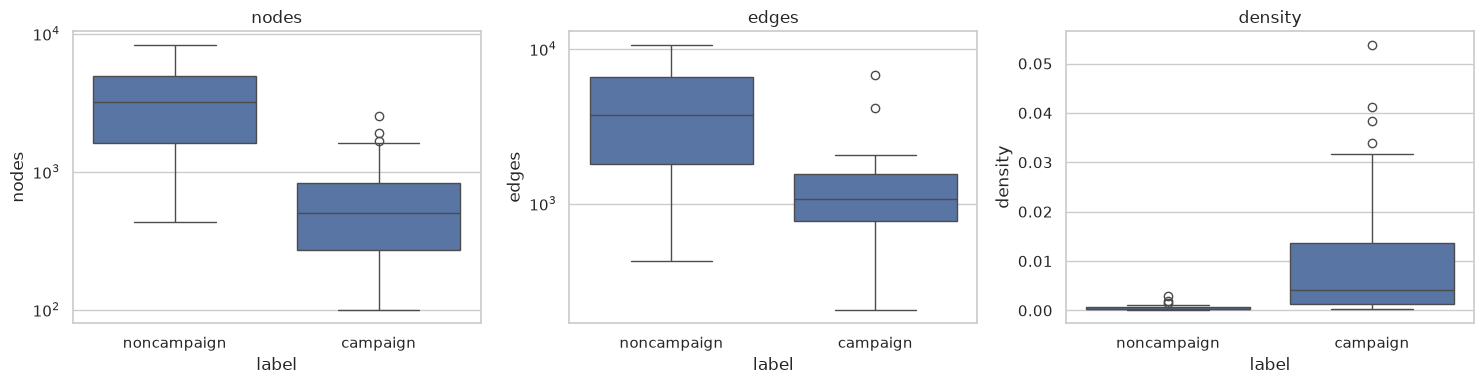

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for column, axis in zip(['nodes', 'edges', 'density'], axes):
    sns.boxplot(data=graphs, x='label', y=column, ax=axis)
    if column != 'density':
        axis.set_yscale('log')
    axis.set_title(column)
plt.tight_layout()

A diferença de tamanho é grande o suficiente para virar um atalho do classificador. Por isso haverá um baseline `size_only` e uma ablação sem contagens brutas.

## 4. Verificar redundância

Correlação alta significa que duas colunas carregam informação parecida. Ela não indica que uma causa a outra.

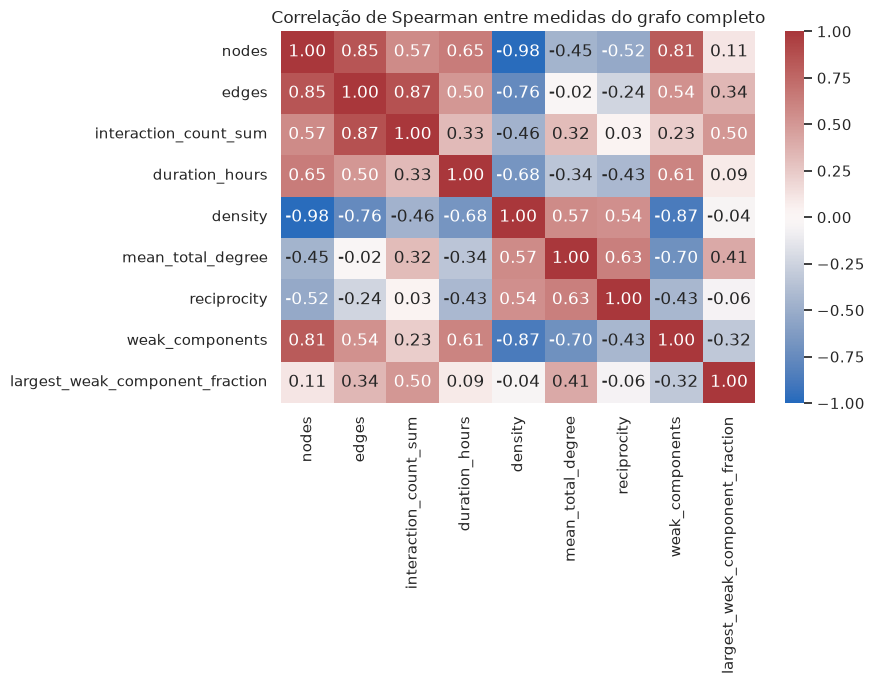

In [6]:
correlation = graphs[compare].corr(method='spearman')
plt.figure(figsize=(9, 7))
sns.heatmap(correlation, vmin=-1, vmax=1, center=0, cmap='vlag', annot=True, fmt='.2f')
plt.title('Correlação de Spearman entre medidas do grafo completo')
plt.tight_layout()

A densidade tem correlação quase perfeita e negativa com o número de nós. A comparação entre classes não deve interpretar densidade isoladamente como sinal de coordenação.

## 5. Validar a tabela de estados parciais

Esperamos 103 arquivos × 2 modalidades × 10 frações = 2.060 linhas. A modalidade `events` controla diretamente o número de arestas; a modalidade `time` controla o relógio.

In [7]:
validation = {
    'rows': len(snapshots),
    'graphs': snapshots['file'].nunique(),
    'modes': sorted(snapshots['partiality_mode'].unique()),
    'fractions': sorted(snapshots['fraction'].unique()),
    'duplicated_keys': snapshots.duplicated(['file', 'partiality_mode', 'fraction']).sum(),
}
validation

{'rows': 2060,
 'graphs': 103,
 'modes': ['events', 'time'],
 'fractions': [np.float64(0.1),
  np.float64(0.2),
  np.float64(0.3),
  np.float64(0.4),
  np.float64(0.5),
  np.float64(0.6),
  np.float64(0.7),
  np.float64(0.8),
  np.float64(0.9),
  np.float64(1.0)],
 'duplicated_keys': np.int64(0)}

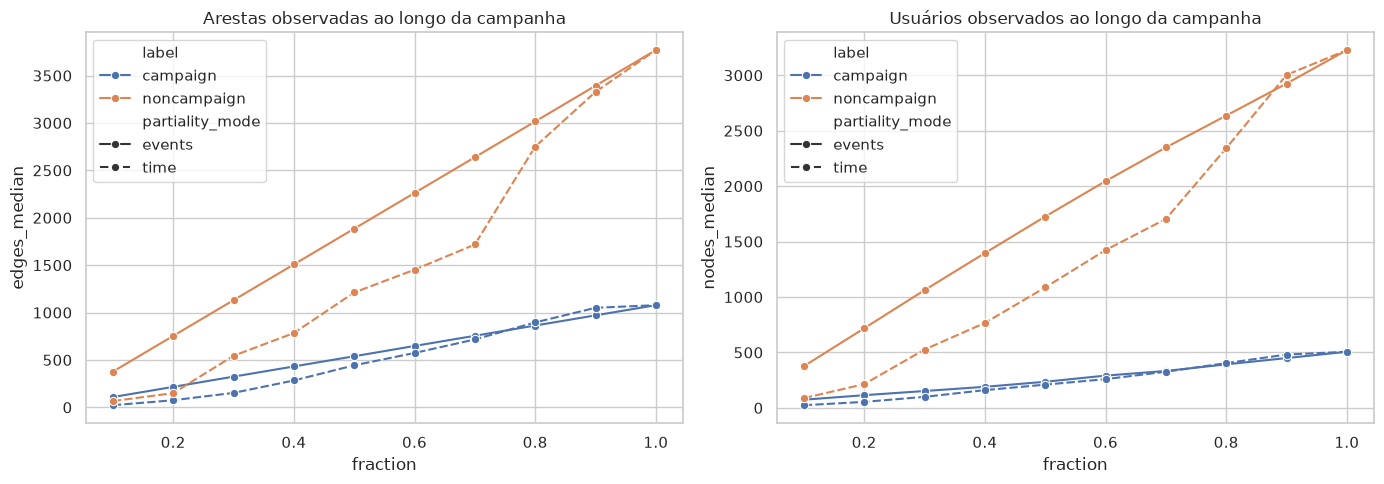

In [8]:
trajectory = (
    snapshots.groupby(['partiality_mode', 'label', 'fraction'])
    .agg(edges_median=('edges', 'median'), nodes_median=('nodes', 'median'))
    .reset_index()
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(data=trajectory, x='fraction', y='edges_median', hue='label', style='partiality_mode', marker='o', ax=axes[0])
sns.lineplot(data=trajectory, x='fraction', y='nodes_median', hue='label', style='partiality_mode', marker='o', ax=axes[1])
axes[0].set_title('Arestas observadas ao longo da campanha')
axes[1].set_title('Usuários observados ao longo da campanha')
plt.tight_layout()

## 6. Observar features normalizadas ao longo do tempo

As medidas abaixo não são simples contagens. Elas ajudam a verificar se existe algum padrão além da escala do grafo. Esta comparação é descritiva; a seleção para o modelo será feita somente no treino.

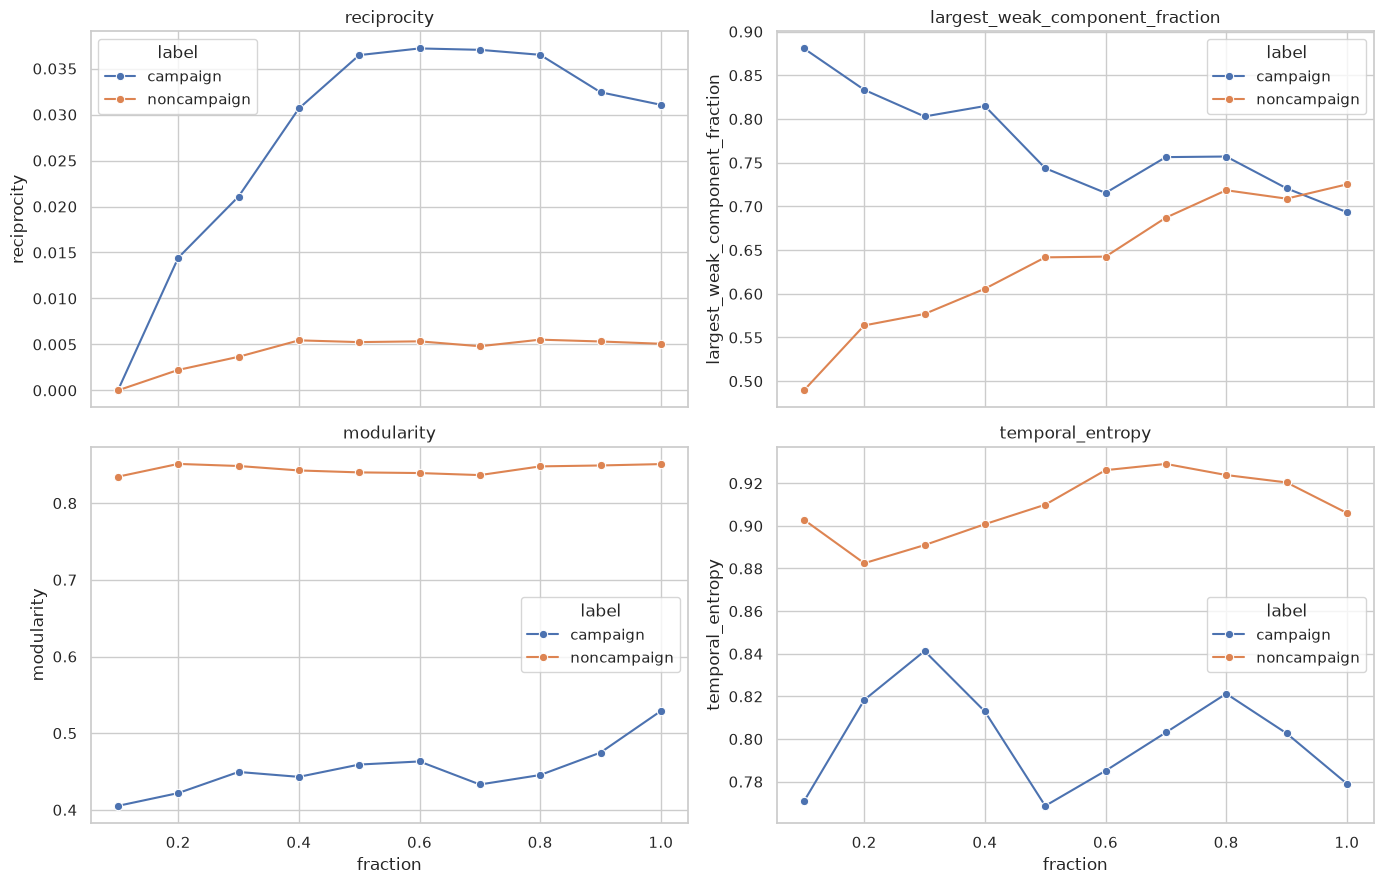

In [9]:
normalized = ['reciprocity', 'largest_weak_component_fraction', 'modularity', 'temporal_entropy']
event_snapshots = snapshots.loc[snapshots['partiality_mode'] == 'events']
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for column, axis in zip(normalized, axes.flat):
    medians = event_snapshots.groupby(['label', 'fraction'], as_index=False)[column].median()
    sns.lineplot(data=medians, x='fraction', y=column, hue='label', marker='o', ax=axis)
    axis.set_title(column)
plt.tight_layout()

## 7. Auditar valores ausentes e infinitos

Snapshots muito iniciais podem ter duração zero ou poucos eventos. Nesses casos, algumas taxas e intervalos não estão definidos. O pipeline de modelagem deverá imputar esses valores usando apenas o conjunto de treino.

In [10]:
numeric = snapshots.select_dtypes(include='number').replace([np.inf, -np.inf], np.nan)
missing = numeric.isna().mean().sort_values(ascending=False)
missing.loc[missing > 0].to_frame('missing_fraction')

,missing_fraction
interevent_seconds_mean,0.012621
interevent_seconds_max,0.012621
interevent_seconds_p90,0.012621
interevent_seconds_median,0.012621


## Conclusões para a próxima etapa

1. A lista oficial de 100 grafos precisa ser resolvida antes do split.
2. Tamanho é um forte fator de confusão e precisa de baseline e ablação próprios.
3. Features derivadas do grafo completo e embeddings ficam fora do primeiro baseline.
4. As duas formas de parcialidade devem ser reportadas separadamente.
5. A próxima etapa é congelar a amostra, criar o split por arquivo e treinar Regressão Logística e Random Forest por fração.